# Proyecto Final - Procesamiento de Imágenes
## Visualización y Exploración del Dataset Hiperespectral (`imaging-5`)

Este cuaderno permite cargar, procesar y visualizar de forma sencilla las imágenes de la carpeta `imaging-5`.

### 🔬 Características del Dataset:
- **Tipo de dato:** Imágenes Hiperespectrales (HSI) en formato estándar **ENVI** (`.hdr` + `.img`).
- **Dimensiones espaciales:** $64 \times 64$ píxeles.
- **Canales espectrales:** $448$ bandas continuas que abarcan desde el rango visible (~$410\text{ nm}$) hasta el infrarrojo de onda corta (SWIR, ~$2510\text{ nm}$).
- **Tipo de valor:** Punto flotante de 32 bits (`float32`), organización por píxel (`interleave = bip`).


In [1]:
import os
import glob
import warnings
import numpy as np
import matplotlib.pyplot as plt
import spectral.io.envi as envi

# Para controles interactivos opcionales
try:
    import ipywidgets as widgets
    from ipywidgets import interact
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

# Suprimir advertencias menores de valores NaN en los archivos
warnings.filterwarnings('ignore', category=UserWarning)

# Configuración visual de matplotlib
plt.rcParams['figure.dpi'] = 110
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('✅ Librerías importadas correctamente.')


✅ Librerías importadas correctamente.


---
## 1. Exploración del Directorio `imaging-5`
Listamos los archivos `.hdr` (encabezados de metadatos) disponibles en la carpeta.


In [2]:
DATA_DIR = 'imaging-5'
hdr_files = sorted(glob.glob(os.path.join(DATA_DIR, '*.hdr')))

print(f'Total de imágenes hiperespectrales encontradas: {len(hdr_files)}')
print('\nPrimeras 5 imágenes:')
for i, f in enumerate(hdr_files[:5]):
    print(f'  [{i}] {os.path.basename(f)}')


Total de imágenes hiperespectrales encontradas: 1383

Primeras 5 imágenes:
  [0] 0_1_0__KK-K-02_KS-K-13_KS-K-11__imaging-5__22_20000_us_2x_HSNR02_2022-06-08T103533_corr_rad_f32.hdr
  [1] 0_1_1__KK-K-02_KS-K-13_KS-K-11__imaging-5__22_20000_us_2x_HSNR02_2022-06-08T103533_corr_rad_f32.hdr
  [2] 0_1_2__KK-K-02_KS-K-13_KS-K-11__imaging-5__22_20000_us_2x_HSNR02_2022-06-08T103533_corr_rad_f32.hdr
  [3] 0_1_3__KK-K-02_KS-K-13_KS-K-11__imaging-5__22_20000_us_2x_HSNR02_2022-06-08T103533_corr_rad_f32.hdr
  [4] 0_1_4__KK-K-02_KS-K-13_KS-K-11__imaging-5__22_20000_us_2x_HSNR02_2022-06-08T103533_corr_rad_f32.hdr


---
## 2. Función de Carga de Imágenes Hiperespectrales
Implementamos una función que lee el archivo de cabecera `.hdr` y el archivo binario `.img`, maneja valores `NaN`, y extrae las longitudes de onda correspondientes a cada una de las 448 bandas.


In [3]:
def cargar_cubo_hiperespectral(hdr_path):
    """
    Carga una imagen hiperespectral ENVI (.hdr / .img).
    Retorna (cubo, longitudes_onda, bandas_rgb, metadata).
    """
    img_envi = envi.open(hdr_path)
    metadata = img_envi.metadata
    
    # Cargar array numérico
    raw_cube = np.asarray(img_envi.load(), dtype=np.float32)
    
    # Reemplazar NaNs por 0.0 para visualización limpia
    cube = np.nan_to_num(raw_cube, nan=0.0)
    
    # Extraer longitudes de onda
    if 'wavelength' in metadata:
        wavelengths = np.array([float(w) for w in metadata['wavelength']])
    else:
        wavelengths = np.arange(cube.shape[2])
        
    # Bandas RGB por defecto (los encabezados ENVI usan indexación base 1)
    if 'default bands' in metadata:
        default_bands = [int(b) - 1 for b in metadata['default bands']]
    else:
        # Aproximación clásica: Rojo ~606nm, Verde ~555nm, Azul ~450nm
        default_bands = [54, 40, 11]
        
    return cube, wavelengths, default_bands, metadata

# Probamos la carga con la primera imagen
ejemplo_hdr = hdr_files[0]
cubo, longitudes_onda, bandas_rgb, meta = cargar_cubo_hiperespectral(ejemplo_hdr)

print(f'Archivo cargado: {os.path.basename(ejemplo_hdr)}')
print(f'Dimensiones del cubo (Alto, Ancho, Bandas): {cubo.shape}')
print(f'Rango espectral: {longitudes_onda[0]:.1f} nm a {longitudes_onda[-1]:.1f} nm')
print(f'Bandas RGB sugeridas: {bandas_rgb} (Longitudes: {longitudes_onda[bandas_rgb[0]]:.1f} nm, {longitudes_onda[bandas_rgb[1]]:.1f} nm, {longitudes_onda[bandas_rgb[2]]:.1f} nm)')


Archivo cargado: 0_1_0__KK-K-02_KS-K-13_KS-K-11__imaging-5__22_20000_us_2x_HSNR02_2022-06-08T103533_corr_rad_f32.hdr
Dimensiones del cubo (Alto, Ancho, Bandas): (64, 64, 448)
Rango espectral: 409.8 nm a 2509.6 nm
Bandas RGB sugeridas: [54, 40, 11] (Longitudes: 606.2 nm, 555.3 nm, 449.8 nm)


### 💡 Método Alternativo: Carga Directa con NumPy Puro (sin dependencias adicionales)
Si en algún entorno no se dispone de la librería `spectral`, podemos cargar directamente el archivo `.img` binario interpretando la estructura ENVI `(lines, samples, bands)` con formato `float32` little-endian (`<f4`).


In [4]:
def cargar_cubo_numpy(hdr_path):
    img_path = os.path.splitext(hdr_path)[0] + '.img'
    
    # Leer dimensiones desde el archivo .hdr
    meta = {}
    with open(hdr_path, 'r', encoding='utf-8') as f:
        for line in f:
            if '=' in line:
                k, v = line.split('=', 1)
                meta[k.strip().lower()] = v.strip()
                
    lines = int(meta.get('lines', 64))
    samples = int(meta.get('samples', 64))
    bands = int(meta.get('bands', 448))
    
    # Lectura binaria directa (BIP: lines, samples, bands)
    raw = np.fromfile(img_path, dtype='<f4')
    cube = raw.reshape((lines, samples, bands))
    cube = np.nan_to_num(cube, nan=0.0)
    return cube, meta

cubo_np, _ = cargar_cubo_numpy(ejemplo_hdr)
print(f'Carga con NumPy exitosa: forma {cubo_np.shape}, mín {cubo_np.min():.2f}, máx {cubo_np.max():.2f}')


Carga con NumPy exitosa: forma (64, 64, 448), mín 0.00, máx 1.46


---
## 3. Visualización en Color Real (RGB) y Falso Color
Dado que las imágenes hiperespectrales poseen 448 canales de reflectancia/radianza con rangos dinámicos específicos, aplicamos un estiramiento de contraste por percentiles (2% a 98%) para obtener una imagen nítida.


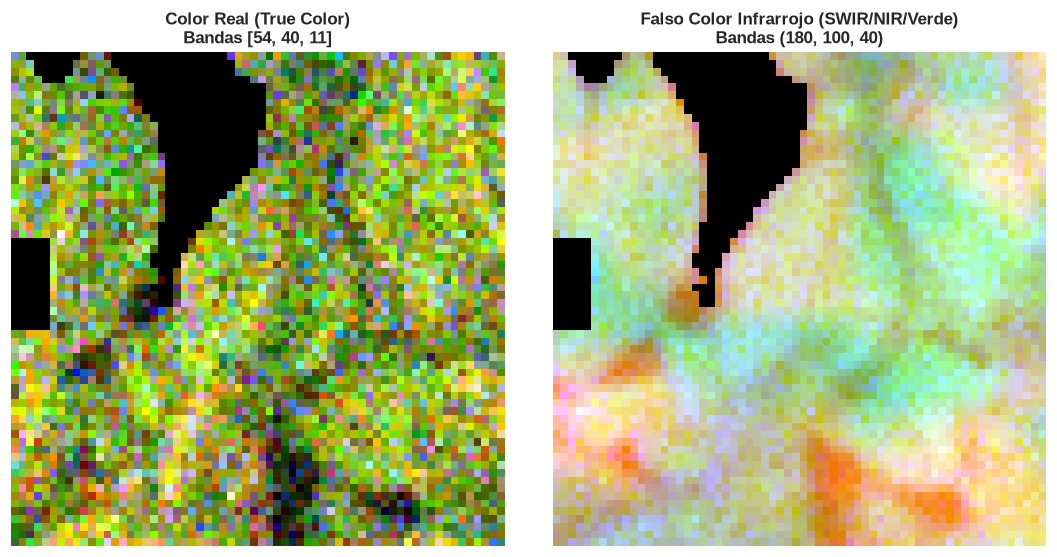

In [5]:
def crear_imagen_rgb(cubo, bandas=(54, 40, 11), p_min=2, p_max=98):
    rgb = cubo[:, :, list(bandas)]
    
    # Estiramiento de contraste por percentiles en cada canal
    rgb_norm = np.zeros_like(rgb)
    for c in range(3):
        canal = rgb[:, :, c]
        vmin, vmax = np.percentile(canal, (p_min, p_max))
        if vmax > vmin:
            rgb_norm[:, :, c] = np.clip((canal - vmin) / (vmax - vmin), 0, 1)
        else:
            rgb_norm[:, :, c] = canal
    return rgb_norm

# 1. Composición Color Real (Visible)
rgb_real = crear_imagen_rgb(cubo, bandas=bandas_rgb)

# 2. Composición Falso Color Infrarrojo (SWIR-1, NIR, Verde)
bandas_falso_color = (180, 100, 40)
rgb_falso = crear_imagen_rgb(cubo, bandas=bandas_falso_color)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(rgb_real)
axes[0].set_title(f'Color Real (True Color)\nBandas {bandas_rgb}', fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(rgb_falso)
axes[1].set_title(f'Falso Color Infrarrojo (SWIR/NIR/Verde)\nBandas {bandas_falso_color}', fontsize=11, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()


---
## 4. Comparación de Bandas Individuales a través del Espectro
Observemos cómo se ve la muestra en diferentes regiones del espectro electromagnético:
- **Visible:** Azul (~450 nm), Verde (~555 nm), Rojo (~650 nm)
- **Infrarrojo Cercano (NIR):** ~770 nm, ~850 nm
- **Infrarrojo de Onda Corta (SWIR):** ~1200 nm, ~1600 nm, ~2200 nm


<>:15: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:15: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/tmp/ipykernel_168798/3805168990.py:15: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  axes[i].set_title(f'Banda {b_idx + 1}\n$\lambda = {longitud:.1f}$ nm', fontsize=10)


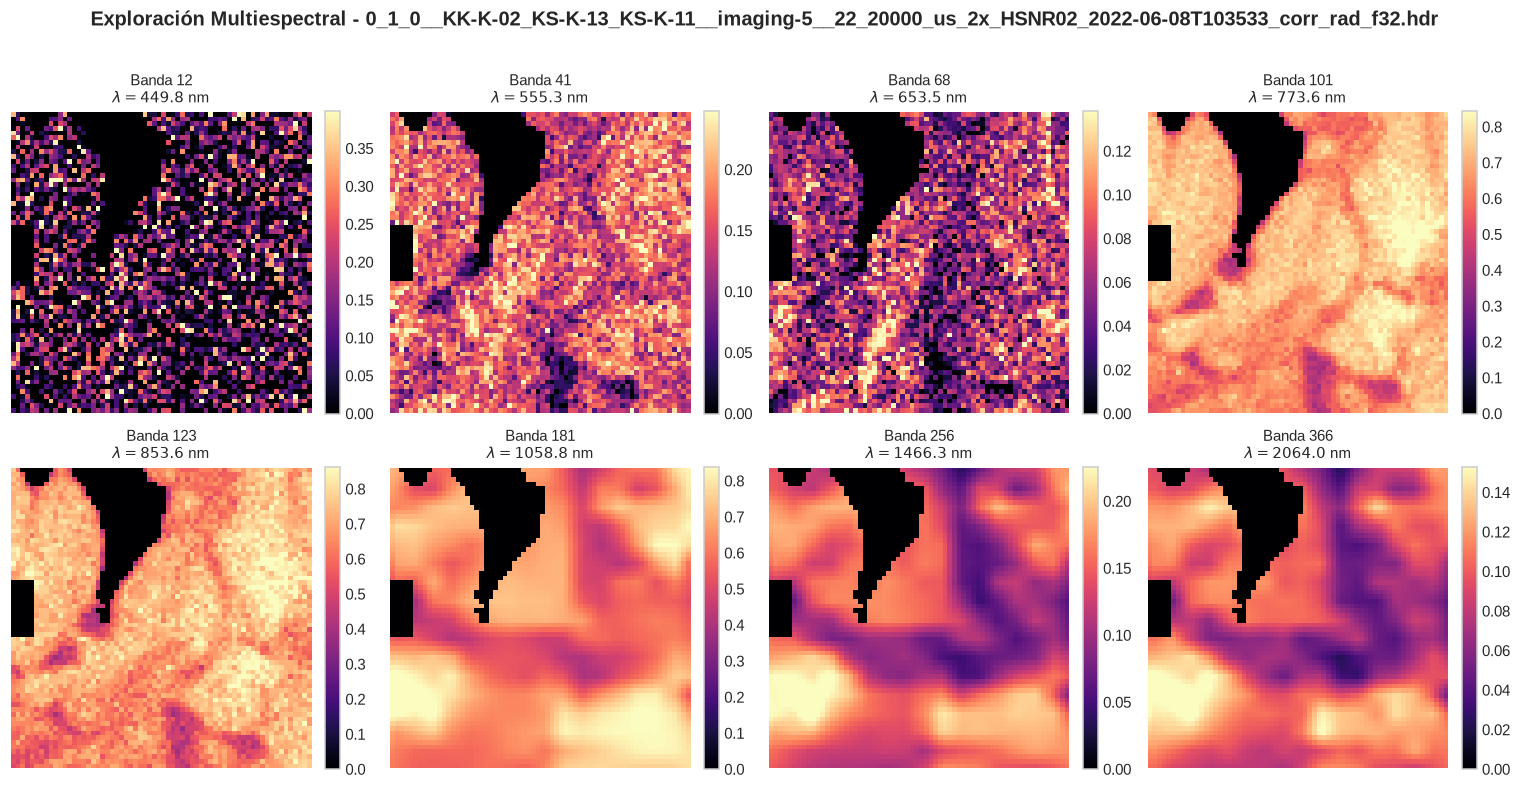

In [6]:
indices_bandas = [11, 40, 67, 100, 122, 180, 255, 365]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for i, b_idx in enumerate(indices_bandas):
    b_idx = min(b_idx, cubo.shape[2] - 1)
    longitud = longitudes_onda[b_idx]
    
    # Extraer banda y normalizar con percentiles
    banda_img = cubo[:, :, b_idx]
    vmin, vmax = np.percentile(banda_img, (2, 98))
    
    im = axes[i].imshow(banda_img, cmap='magma', vmin=vmin, vmax=vmax)
    axes[i].set_title(f'Banda {b_idx + 1}\n$\lambda = {longitud:.1f}$ nm', fontsize=10)
    axes[i].axis('off')
    plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)

plt.suptitle(f'Exploración Multiespectral - {os.path.basename(ejemplo_hdr)}', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 5. Análisis de la Firma Espectral de Píxeles
Cada píxel $(y, x)$ contiene una **firma espectral** (el vector de 448 reflectancias/radianzas en función de $\lambda$). Esta curva es la 'huella dactilar' del material observado.


<>:27: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:27: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/tmp/ipykernel_168798/3060650239.py:27: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  ax_spec.set_xlabel('Longitud de onda $\lambda$ (nm)')


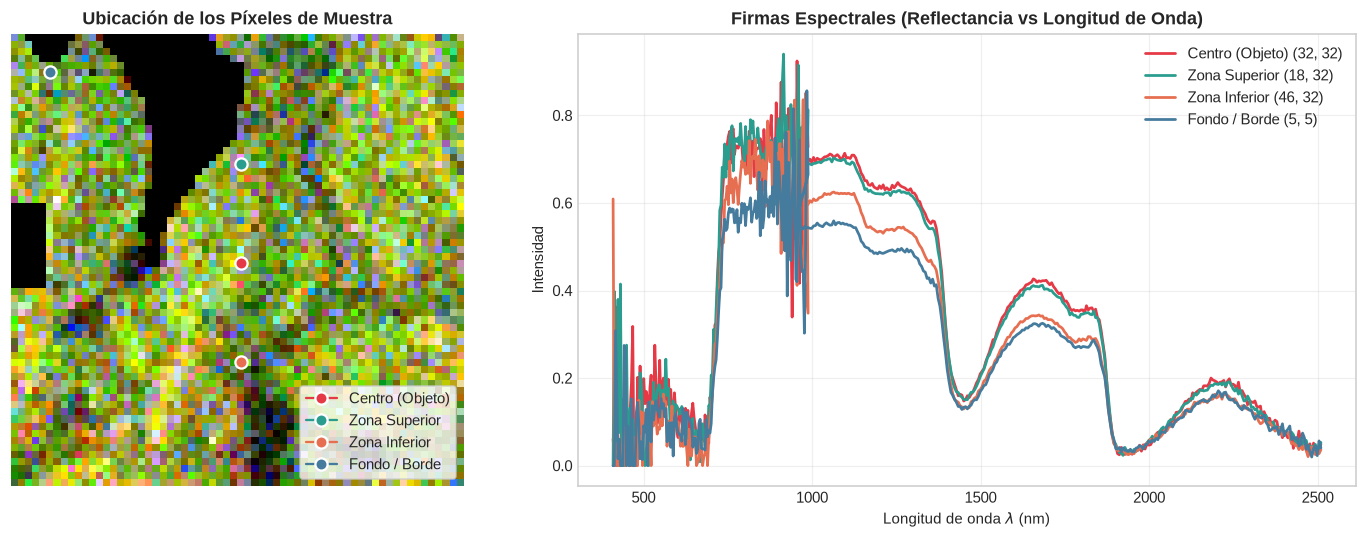

In [7]:
# Coordenadas de ejemplo para comparar distintos puntos de la muestra
puntos_interes = {
    'Centro (Objeto)': (32, 32),
    'Zona Superior': (18, 32),
    'Zona Inferior': (46, 32),
    'Fondo / Borde': (5, 5)
}

colores = ['#e63946', '#2a9d8f', '#e76f51', '#457b9d']

fig, (ax_img, ax_spec) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={'width_ratios': [1, 1.4]})

# Mostrar imagen RGB con la ubicación de los puntos
ax_img.imshow(rgb_real)
for (nombre, (py, px)), col in zip(puntos_interes.items(), colores):
    ax_img.plot(px, py, marker='o', markersize=8, markeredgecolor='white', markeredgewidth=1.5, color=col, label=nombre)
ax_img.set_title('Ubicación de los Píxeles de Muestra', fontweight='bold')
ax_img.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.8)
ax_img.axis('off')

# Graficar las firmas espectrales
for (nombre, (py, px)), col in zip(puntos_interes.items(), colores):
    firma = cubo[py, px, :].flatten()
    ax_spec.plot(longitudes_onda, firma, label=f'{nombre} ({py}, {px})', color=col, lw=1.8)

ax_spec.set_title('Firmas Espectrales (Reflectancia vs Longitud de Onda)', fontweight='bold')
ax_spec.set_xlabel('Longitud de onda $\lambda$ (nm)')
ax_spec.set_ylabel('Intensidad')
ax_spec.grid(True, alpha=0.3)
ax_spec.legend()

plt.tight_layout()
plt.show()


---
## 6. Galería de Muestras del Dataset
Visualizamos una cuadrícula de 12 imágenes del dataset para apreciar la diversidad de las muestras en `imaging-5`.


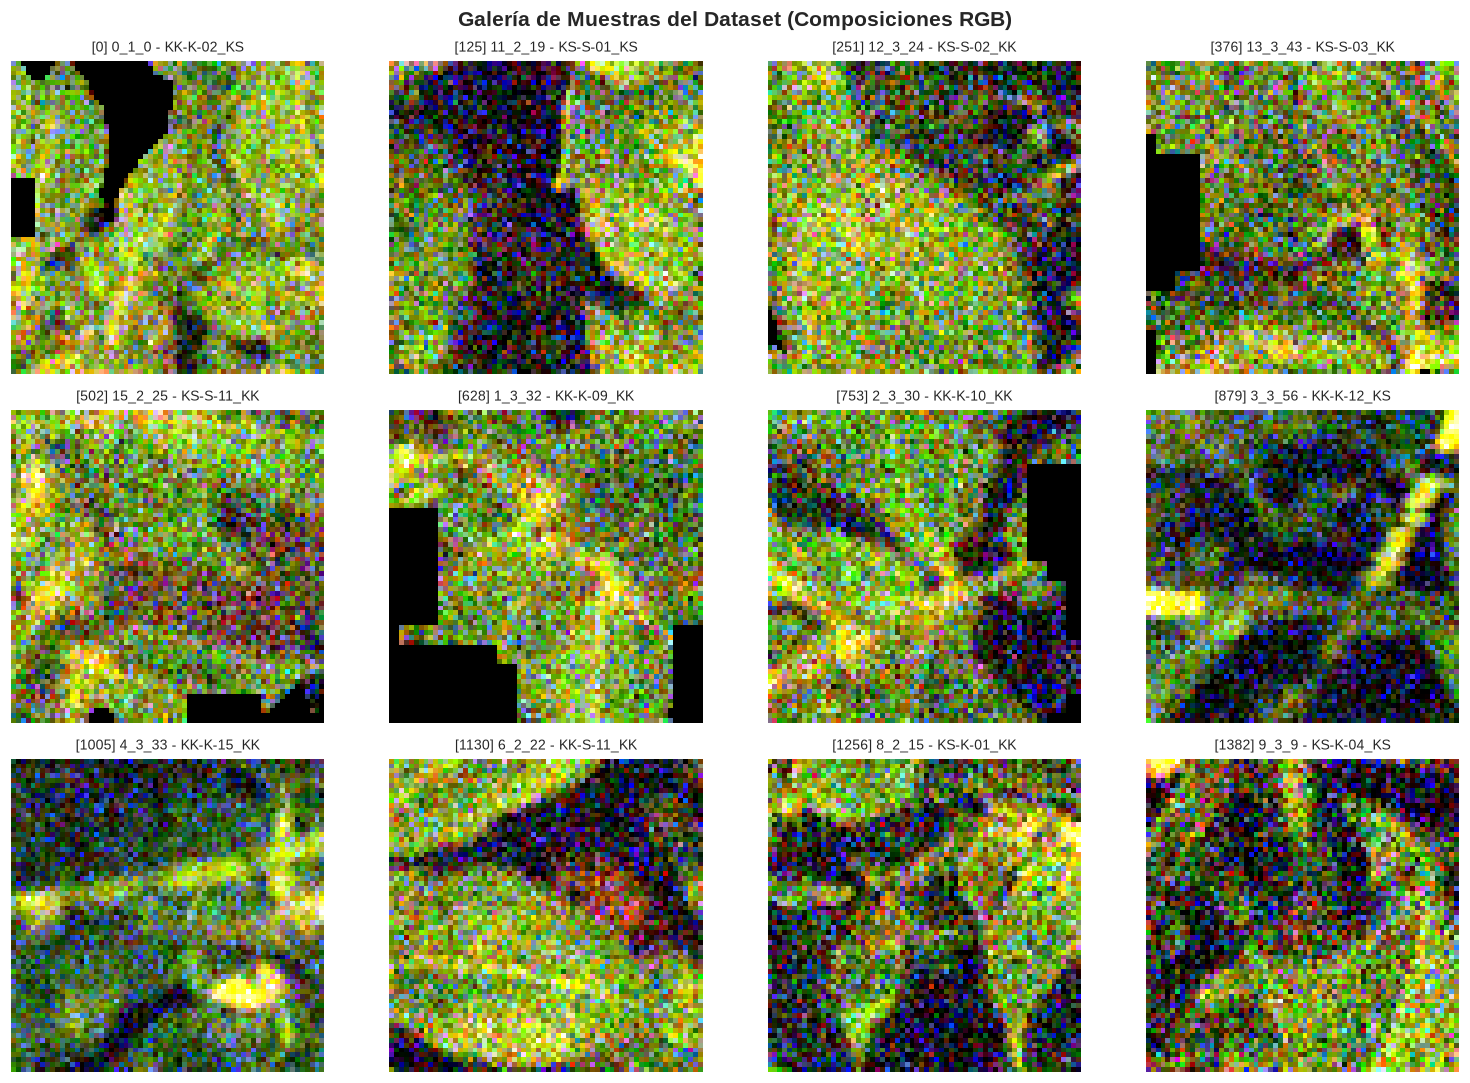

In [8]:
# Seleccionar 12 imágenes espaciadas del conjunto disponible
num_muestras = min(12, len(hdr_files))
indices_muestras = np.linspace(0, len(hdr_files) - 1, num_muestras, dtype=int)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for idx, ax in zip(indices_muestras, axes):
    ruta_h = hdr_files[idx]
    c, _, b_rgb, _ = cargar_cubo_hiperespectral(ruta_h)
    rgb = crear_imagen_rgb(c, bandas=b_rgb)
    
    # Nombre resumido para el título
    partes = os.path.basename(ruta_h).split('__')
    nombre_corto = partes[0] + (' - ' + partes[1][:10] if len(partes) > 1 else '')
    ax.imshow(rgb)
    ax.set_title(f'[{idx}] {nombre_corto}', fontsize=9)
    ax.axis('off')

plt.suptitle('Galería de Muestras del Dataset (Composiciones RGB)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 7. Explorador Interactivo
Permite seleccionar dinámicamente cualquier imagen del dataset y explorar sus bandas individuales o la composición RGB mediante controles deslizantes.


<>:21: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:21: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
/tmp/ipykernel_169244/2051400981.py:21: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  ax.set_title(f'Banda {banda_num} ($\lambda = {wls[b_idx]:.1f}$ nm)\n{os.path.basename(ruta_sel)[:35]}...', fontsize=10)


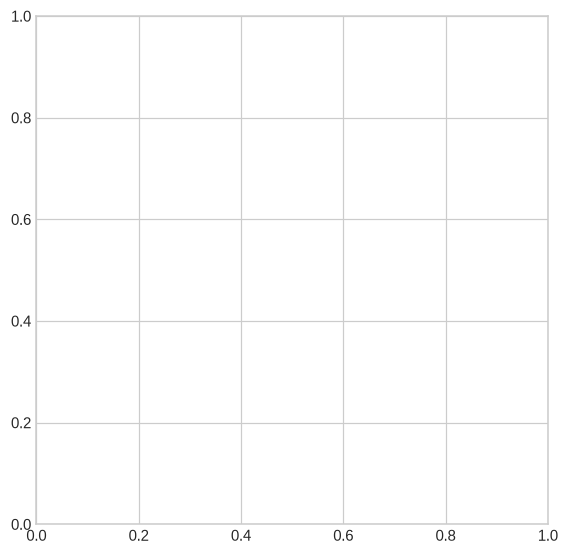

interactive(children=(IntSlider(value=0, description='Imagen:'), Dropdown(description='Modo:', options=('RGB (…

In [5]:
if WIDGETS_AVAILABLE:
    @interact(
        imagen_idx=widgets.IntSlider(min=0, max=min(len(hdr_files)-1, 100), step=1, value=0, description='Imagen:'),
        modo=widgets.Dropdown(options=['RGB (Color Real)', 'Banda Individual'], value='RGB (Color Real)', description='Modo:'),
        banda_num=widgets.IntSlider(min=1, max=448, step=1, value=55, description='Banda (1-448):')
    )
    def explorar_interactivo(imagen_idx, modo, banda_num):
        ruta_sel = hdr_files[imagen_idx]
        c, wls, b_rgb, _ = cargar_cubo_hiperespectral(ruta_sel)
        
        fig, ax = plt.subplots(figsize=(6, 6))
        if modo == 'RGB (Color Real)':
            img_disp = crear_imagen_rgb(c, bandas=b_rgb)
            ax.imshow(img_disp)
            ax.set_title(f'RGB: {os.path.basename(ruta_sel)[:35]}...\nBandas {b_rgb}', fontsize=10)
        else:
            b_idx = banda_num - 1
            banda_data = c[:, :, b_idx]
            vmin, vmax = np.percentile(banda_data, (2, 98))
            im = ax.imshow(banda_data, cmap='viridis', vmin=vmin, vmax=vmax)
            ax.set_title(f'Banda {banda_num} ($\lambda = {wls[b_idx]:.1f}$ nm)\n{os.path.basename(ruta_sel)[:35]}...', fontsize=10)
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.axis('off')
        plt.show()
else:
    print('ℹ️ ipywidgets no está activo. Puedes ejecutar las celdas estáticas anteriores normalmente.')
